In [ ]:
#| default_exp DistBaseExact

In [ ]:
#| hide
# Imports for the nbdev development environment
import nbdev
from nbdev.showdoc import *
from fastcore.basics import patch

In [ ]:
#| export
import numpy as np
from scipy.stats import norm
from scipy.stats import expectile

import jax.numpy as jnp
from jax import jit
from functools import partial

import itertools as it

from pyCRLD.Agents.Base import abase
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Utils.Helpers import *

In [ ]:
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Utils import FlowPlot as fp

import numpy as np
import itertools as it
import matplotlib.pyplot as plt
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from datetime import datetime

In [ ]:
# Define environment
env = EcologicalPublicGood(N=2, f=1.2, c=5, m=-4, qc=0.2, qr=0.1, degraded_choice=True)
env

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


EcologicalPublicGood_2_1.2_5_-4_0.2_0.1_DegChoi

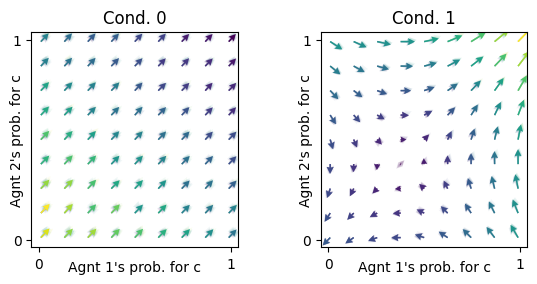

In [ ]:
# Init enviornment and MultiAgentEnvironment-interface
mae = stratAC(env=env, learning_rates=0.1, discount_factors=0.9, use_prefactor=True)

x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
ax = fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16)

In [ ]:
#| export
def compute_discretization_grid(Rmin, # Minimum reward obtainable
                                Rmax, # Maximum reward obtainable
                                Nr # Number of bin
                                ) -> tuple: # Gridpoints, Width 
    gridpoints = np.linspace(Rmin, Rmax, Nr)
    width  = np.round(gridpoints[1] - gridpoints[0], 8)
    return gridpoints, width

In [ ]:
gridpoints, width = compute_discretization_grid(env.R.min(), env.R.max(), 29)
gridpoints

array([-4.  , -3.75, -3.5 , -3.25, -3.  , -2.75, -2.5 , -2.25, -2.  ,
       -1.75, -1.5 , -1.25, -1.  , -0.75, -0.5 , -0.25,  0.  ,  0.25,
        0.5 ,  0.75,  1.  ,  1.25,  1.5 ,  1.75,  2.  ,  2.25,  2.5 ,
        2.75,  3.  ])

In [ ]:
width

0.25

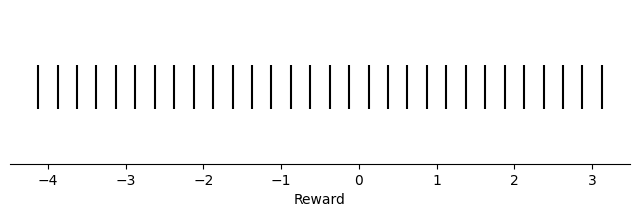

In [ ]:
plt.figure(figsize=(8,2))
plt.gca().spines[['right', 'top', 'left']].set_visible(False)
boundaries = np.array(list(gridpoints - width/2) + 
                      [gridpoints[-1] + width/2])
plt.scatter(boundaries, np.zeros_like(boundaries), marker="|", c='k', s=1000)
plt.yticks([]); plt.xlabel('Reward');

In [ ]:
#| export
def compute_Risjasr(env, # The env object
                    nr,  # The number of reward bins
                    discretization_sigma # Width of the discritization normal distribution
                   ) -> np.ndarray: # Reward distribution
    # get the discretization grid
    points, width = compute_discretization_grid(env.R.min(), env.R.max(), nr)

    # init the reward distribution tensor
    Risjasr = np.ones(env.R.shape + (nr,)) * -1  # last dim is distrib
        
    # scale the standard devision with the width of the discritization grid 
    sig = discretization_sigma*width

    # go through the reward tensor of the envrionment
    for index, _ in np.ndenumerate(env.R):
        valr = env.R[index]  # the actual environmental reward value 
        for r in range(nr):
            if r==nr-1: # last interval
                prop = float(valr >= points[r]-width/2 and valr <= points[r]+width/2)
            else:
                prop = float(valr >= points[r]-width/2 and valr < points[r]+width/2)
            Risjasr[index +(r,)] = prop

    return Risjasr

In [ ]:
nr = 29
sig = 0.1
Risjasr = compute_Risjasr(env, nr, sig)
gpoints, wdth = compute_discretization_grid(env.R.min(), env.R.max(), nr)

def plot_Risjasr(i,s,a1,a2,s_, Rr=Risjasr,gpoints=gpoints,wdth=wdth):
    plt.figure(figsize=(8,3))
    plt.gca().spines[['right', 'top', 'left']].set_visible(False)
    plt.bar(gpoints, Rr[i,s,a1,a2,s_,:], width=0.95*wdth, color='k')
    rv = env.R[i,s,a1,a2,s_]
    plt.plot([rv, rv], [0.0, 0.05], c='red', lw=5)
    plt.xlabel("Reward");

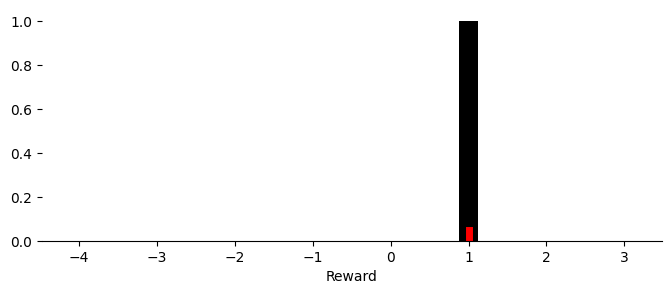

In [ ]:
plot_Risjasr(i=0,s=1,a1=0,a2=0,s_=1)

In [ ]:
#| export
# Smoothed Bellman Kronecker delta for Bellman equation
def compute_b_ivrv_(env, # env object
                    nr, # number of bins
                    discretization_sigma, # width of discretization normal distribution
                    gamma # discount factor
                   ) -> np.ndarray: 
    
    points, width = compute_discretization_grid(env.R.min(), env.R.max(), nr)
    sigma = discretization_sigma * width
    b_ivrv_ = np.ones((env.N, nr, nr, nr)) * -1

    for v in range(nr):
        for r in range(nr):
            for v_ in range(nr):
                
                valv = (1 - gamma[0]) * points[r] + gamma[0] * points[v_]
                
                # gaussian distribution around valq with std `sig` 
                if v==nr-1: # last interval
                    prop = float(valv >= points[v]-width/2) * float(valv <= points[v]+width/2)
                else:
                    prop = float(valv >= points[v]-width/2) * float(valv < points[v]+width/2)
                    
                b_ivrv_[:,v,r,v_] = prop
    return b_ivrv_

In [ ]:
#| export
# Smoothed Bellman Kronecker delta for prediction error
def compute_b_idvrv_(env,
                     nr, 
                     discretization_sigma,
                     gamma
                    ) -> np.ndarray:
    points, width = compute_discretization_grid(env.R.min(), env.R.max(), nr)
    new_points = np.linspace(points.min() - points.max(), points.max() - points.min(), nr)
    new_width = new_points[1] - new_points[0]
    sigma = discretization_sigma * new_width
    b_idvrv_ = np.ones((env.N, nr, nr, nr, nr)) * -1

    for d in range(nr):
        for v in range(nr):
            for r in range(nr):
                for v_ in range(nr):
                
                    vald = (1-gamma[0])*points[r] + gamma[0]*points[v_] - points[v] 
                
                    # gaussian distribution around valq with std `sig` 
                    if d==nr-1: # last interval
                        prop = float((vald >= new_points[d]-new_width/2 and vald <= new_points[d]+new_width/2))
                    else:
                        prop = float((vald >= new_points[d]-new_width/2 and vald < new_points[d]+new_width/2))
                    
                    b_idvrv_[:,d,v,r,v_] = prop
    return b_idvrv_

In [ ]:
#| export
class distbase(abase):
    """
    Base class for deterministic strategy-average independent (multi-agent)
    temporal-difference reinforcement learning in strategy space.        
    """
    
    def __init__(self,
                 env, # An environment object
                 nr_reward_bins, # The number of bins to resolve rewards
                 discretization_sigma, # standard div for reward discretization
                 learning_rates, # agents' learning rates
                 discount_factors, # agents' discount factors
                 choice_intensities=1.0, # agents' choice intensities
                 opteinsum=True,  # optimize einsum functions
                 **kwargs):

        self.env = env
        Tt = env.T; assert np.allclose(Tt.sum(-1), 1)
        Rt = env.R 
        super().__init__(Tt, Rt, discount_factors, True, opteinsum)
        self.F = jnp.array(env.F)

        # learning rates
        self.alpha = make_variable_vector(learning_rates, self.N)

        # intensity of choice
        self.beta = make_variable_vector(choice_intensities, self.N)
        
        # discount factors
        self.gamma = make_variable_vector(discount_factors, self.N)
        
        # number of reward bins
        self.nr = nr_reward_bins
        
        # reward discretization deviation 
        self.discsig = discretization_sigma
        
        # discretization grid
        disc_grid = compute_discretization_grid(env.R.min(), env.R.max(), self.nr)
        self.gridpoints = disc_grid[0]
        self.gridwidth = disc_grid[1]
        
        # reward tensor distribution
        self.Rr = compute_Risjasr(env, self.nr, self.discsig)
        
        # Bellman ivrv_
        self.b_ivrv_ = compute_b_ivrv_(env, self.nr, self.discsig, self.gamma)
        
        # Bellman idvrv_
        self.b_idvrv_ = compute_b_idvrv_(env, self.nr, self.discsig, self.gamma)

In [ ]:
db = distbase(env,
              nr_reward_bins=21,
              discretization_sigma=0.25,
              learning_rates=0.1,
              discount_factors=0.9)

In [ ]:
#| export
@partial(jit, static_argnums=0)    
def Risr(self:distbase, Xisa):
    i = 0; s = 1; sprim = 2; r=3; b2d = list(range(4, 4+self.N))
    Risjasr = jnp.array(self.Rr)
    
    X4einsum = list(it.chain(*zip(Xisa,
                            [[s, b2d[a]] for a in range(self.N)])))

    args = X4einsum + [self.T, [s]+b2d+[sprim],
                       Risjasr, [i, s]+b2d+[sprim, r], [i, s, r]]

    return jnp.einsum(*args, optimize=self.opti)

distbase.Risr = Risr  # Monkey-patching - possibly problematic?

In [ ]:
X = jnp.array(mae.random_softmax_strategy())

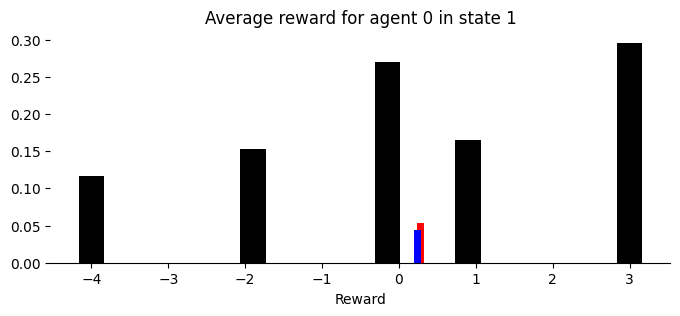

In [ ]:
def plot_Risr(i, s, Rr=Risr,gpoints=gpoints,wdth=wdth):
    plt.figure(figsize=(8,3))
    plt.gca().spines[['right', 'top', 'left']].set_visible(False)
    plt.bar(gpoints, Rr[i,s,:], width=0.95*wdth, color='k')
    ris = mae.Ris(X)[i,s]
    risd = np.dot(gpoints, Rr[i,s,:])
    plt.plot([ris, ris], [0.0, 0.05], c='red', lw=5)
    plt.plot([risd, risd], [0.0, 0.04], c='blue', lw=5)
    plt.title("Average reward for agent "+str(i)+" in state "+str(s))
    plt.xlabel("Reward")

plot_Risr(i=0, s=1, Rr=db.Risr(X), gpoints=db.gridpoints, wdth=db.gridwidth)

In [ ]:
#| export
@partial(jit, static_argnums=0)    
def M_iww_(self:distbase, 
           Xisa  # Behavior profiles
          ) -> jnp.ndarray:
    Tss = self.Tss(Xisa)
    Risr = self.Risr(Xisa)
    b_ivrv_ = self.b_ivrv_

    i=0; v=1; r=2; v_=3; s=4; s_=5

    M = jnp.einsum(b_ivrv_, [i,v,r,v_], Risr, [i, s, r], Tss, 
                   [s, s_], [i, s, v_, s_, v], optimize=self.opti)
    jnp.allclose(M.sum((-2,-1)), 1.0)
    return M

distbase.M_iww_ = M_iww_  # Monkey-patching - possibly problematic?

In [ ]:
#| export
@partial(jit, static_argnums=0)
def Visv(self:distbase,
        Xisa  # Behavior profiles
        ) -> jnp.ndarray:
    M_iww_ = self.M_iww_(Xisa)
    Visv = jnp.ones((self.N, self.Z, self.nr)) * -1

    for i in range(self.N):
        mat = M_iww_[i].reshape(self.Z*self.nr, self.Z*self.nr)
        _pS = compute_stationarydistribution(mat)
        ix = jnp.max(jnp.where(_pS.mean(0)!=-10, jnp.arange(_pS.shape[0]), -1))
        pS = _pS[:, ix]
        
        Ps = pS.reshape(self.Z, self.nr).sum(-1)
        # assert jnp.allclose(self.Ps(Xisa), Ps, atol=1e-4)

        VIsv = pS.reshape(self.Z, self.nr) / pS.reshape(self.Z, self.nr).sum(-1, keepdims=True)
        
        Visv = Visv.at[i, ...].set(VIsv)

        # Visv[i, ...] = VIsv

    return Visv

distbase.Visv = Visv  # Monkey-patching - possibly problematic?

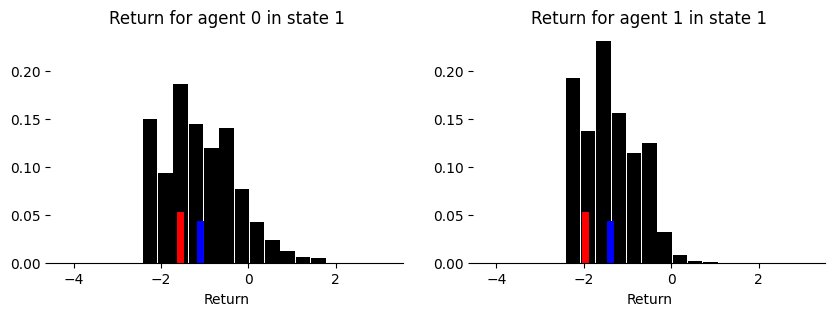

In [ ]:
def plot_V2sv(s, Vv=Visv,gpoints=gpoints,wdth=wdth):
    fig, axes = plt.subplots(1, 2, figsize=(10,3))
    for i, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Vv[i,s,:], width=0.95*wdth, color='k')
        vis = mae.Vis(X)[i,s]
        visd = np.dot(gpoints, Vv[i,s,:])
        ax.plot([visd, visd], [0.0, 0.04], c='blue', lw=5)
        ax.plot([vis, vis], [0.0, 0.05], c='red', lw=5)
        ax.set_xlabel("Return")
        ax.set_title("Return for agent "+str(i)+" in state "+str(s))
        ax.set_ylim([0, np.max(Vv[:,s,:])+0.01])
    

plot_V2sv(s=1, Vv=db.Visv(X), gpoints=db.gridpoints, wdth=db.gridwidth)

In [ ]:
db.Visv(X).sum(-1)

Array([[0.99999994, 1.        ],
       [1.0000001 , 1.        ]], dtype=float32)

In [ ]:
#| export
@partial(jit, static_argnums=0)
def nextVisav(self:distbase,
              Xisa  # Behavior profiles
             ) -> jnp.ndarray:
    
    Visv = self.Visv(Xisa)
    
    i = 0; a = 1; s = 2; s_ = 3; r = 4
    j2k = list(range(6, 6+self.N-1))  # other agents
    b2d = list(range(6+self.N-1, 6+self.N-1 + self.N))  # all actions
    e2f = list(range(5+2*self.N, 5+2*self.N + self.N-1))  # all other acts

    sumsis = [[j2k[l], s, e2f[l]] for l in range(self.N-1)]  # sum inds
    otherX = list(it.chain(*zip((self.N-1)*[Xisa], sumsis)))
                                
    args = [self.Omega, [i]+j2k+[a]+b2d+e2f] + otherX +\
        [self.T, [s]+b2d+[s_], Visv, [i, s_, r], [i, s, a, r]]
    
    nextVisav = jnp.einsum(*args, optimize=self.opti)

    return nextVisav

distbase.nextVisav = nextVisav  # Monkey-patching - possibly problematic?

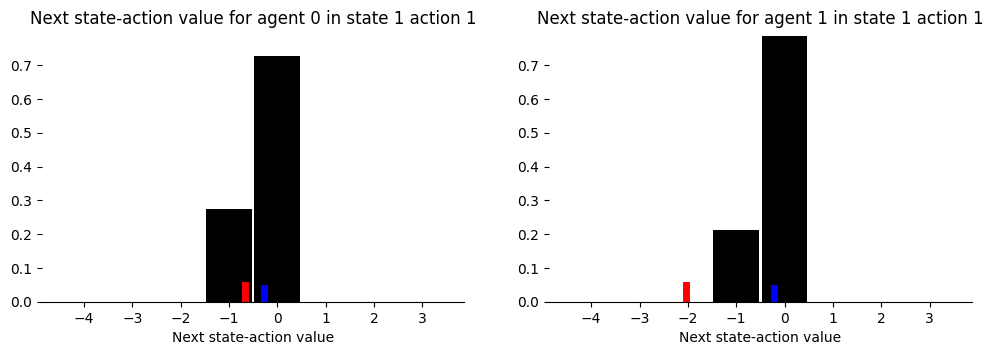

In [ ]:
def plot_nextV2sav(s, a, Vv=nextVisav, Xisa=X, gpoints=gpoints,wdth=wdth):
    fig, axes = plt.subplots(1, 2, figsize=(12,3.5))
    for i, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Vv[i,s,a,:], width=0.95*wdth, color='k')
        nvisa = mae.NextVisa(Xisa)[i,s,a]
        nvisad = np.dot(gpoints, Vv[i,s,a,:])
        ax.plot([nvisad, nvisad], [0.0, 0.04], c='blue', lw=5)
        ax.plot([nvisa, nvisa], [0.0, 0.05], c='red', lw=5)
        ax.set_xlabel("Next state-action value")
        ax.set_title("Next state-action value for agent "+str(i)+" in state "+str(s)+" action "+str(a))
        ax.set_ylim([0, np.max(Vv[:,s,a,:])+0.01])
    

plot_nextV2sav(s=1, a=1, Vv=db.nextVisav(X), Xisa=X, gpoints=db.gridpoints, wdth=db.gridwidth)

In [ ]:
#| export
@partial(jit, static_argnums=0)
def Risar(self:distbase,
          Xisa  # Behavior profiles
         ) -> jnp.ndarray:
    
    i = 0; a = 1; s = 2; s_ = 3; r = 4  # Variables
    j2k = list(range(5, 5+self.N-1))  # other agents
    b2d = list(range(5+self.N-1, 5+self.N-1 + self.N))  # all actions
    e2f = list(range(4+2*self.N, 4+2*self.N + self.N-1))  # all other acts
    Risjasr = self.Rr
 
    sumsis = [[j2k[l], s, e2f[l]] for l in range(self.N-1)]  # sum inds
    otherX = list(it.chain(*zip((self.N-1)*[Xisa], sumsis)))

    args = [self.Omega, [i]+j2k+[a]+b2d+e2f] + otherX\
        + [self.T, [s]+b2d+[s_], Risjasr, [i, s]+b2d+[s_, r],
            [i, s, a, r]]
    Risar = jnp.einsum(*args, optimize=self.opti)
    return Risar

distbase.Risar = Risar # Monkey-patching - possibly problematic?

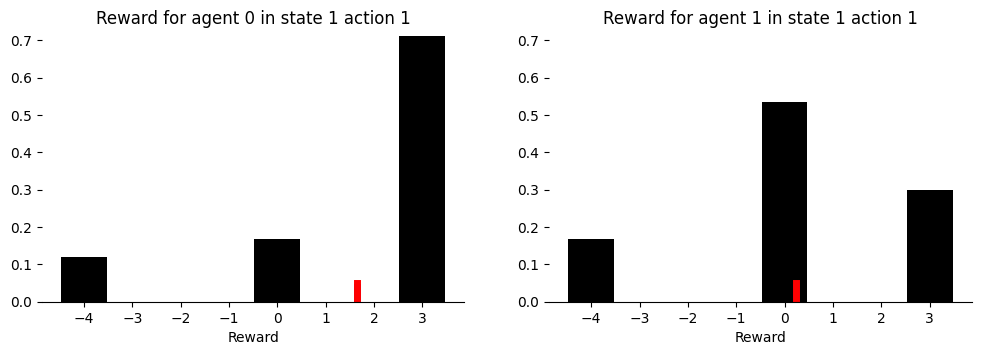

In [ ]:
def plot_R2sar(s, a, Rr=Risar, Xisa=X, gpoints=gpoints,wdth=wdth):
    fig, axes = plt.subplots(1, 2, figsize=(12,3.5))
    for i, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Rr[i,s,a,:], width=0.95*wdth, color='k')
        risa = mae.Risa(Xisa)[i,s,a]
        risad = np.dot(gpoints, Rr[i,s,a,:])
        ax.plot([risad, risad], [0.0, 0.04], c='blue', lw=5)
        ax.plot([risa, risa], [0.0, 0.05], c='red', lw=5)
        ax.set_xlabel("Reward")
        ax.set_title("Reward for agent "+str(i)+" in state "+str(s)+" action "+str(a))
        ax.set_ylim([0, np.max(Rr[:,s,a,:])+0.01])
    

plot_R2sar(s=1, a=1, Rr=db.Risar(X), Xisa=X, gpoints=db.gridpoints, wdth=db.gridwidth)

In [ ]:
#| export
@partial(jit, static_argnums=0)
def Disad(self:distbase,
          Xisa  # Behavior profiles
         ) -> jnp.ndarray:
    # Compute needed tensors
    Risar = self.Risar(Xisa)
    Visv = self.Visv(Xisa)
    nextVisav = self.nextVisav(Xisa)
    # Reformat Visv
    Visav = jnp.zeros((2, 2, 2, self.nr))
    Visav = Visav.at[:, :, 0, :].set(Visv)
    Visav = Visav.at[:, :, 1, :].set(Visv)

    b_idvrv_ = self.b_idvrv_

    i=0; d=1; v=2; r=3; v_=4; s=5; a=6; s_=7

    Disad = jnp.einsum(b_idvrv_, [i,d,v,r,v_], Risar, [i,s,a,r], nextVisav, [i,s,a,v_], 
                      Visav, [i,s,a,v], [i, s, a, d])
    return Disad

distbase.Disad = Disad

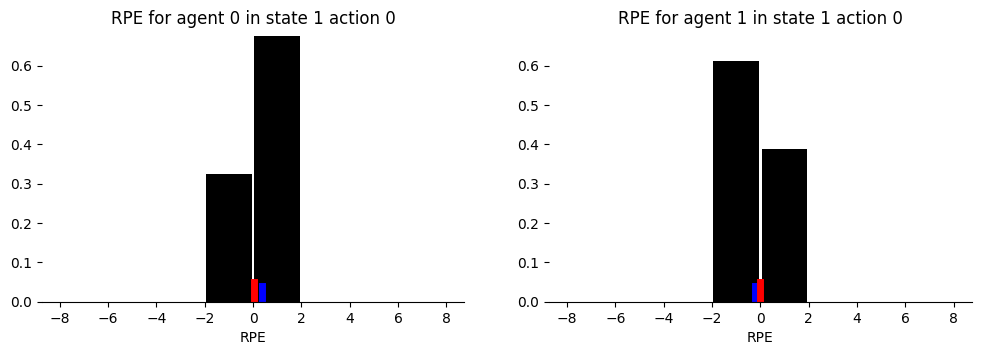

In [ ]:
def plot_D2sad(s, a, Dd=Disad, Xisa=X, gpoints=gpoints,wdth=wdth):
    newpoints = np.linspace(gpoints.min() - gpoints.max(), gpoints.max() - gpoints.min(), db.nr)
    newwidth = np.round(newpoints[1] - newpoints[0], 8)
    fig, axes = plt.subplots(1, 2, figsize=(12,3.5))
    for i, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(newpoints, Dd[i,s,a,:], width=0.95*newwidth, color='k')
        disa = mae.RPEisa(Xisa)[i,s,a]
        disad = np.dot(newpoints, Dd[i,s,a,:])
        ax.plot([disad, disad], [0.0, 0.04], c='blue', lw=5)
        ax.plot([disa, disa], [0.0, 0.05], c='red', lw=5)
        ax.set_xlabel("RPE")
        ax.set_title("RPE for agent "+str(i)+" in state "+str(s)+" action "+str(a))
        ax.set_ylim([0, np.max(Dd[:,s,a,:])+0.01])
    

plot_D2sad(s=1, a=0, Dd=db.Disad(X), Xisa=X, gpoints=db.gridpoints, wdth=db.gridwidth)

In [ ]:
#| export
# Compute RPE from averaging Disad
@partial(jit, static_argnums=(0,2))
def RPEisa(self:distbase,
          Xisa,  # Behavior profiles
          norm=False) -> jnp.ndarray:
    gpoints = self.gridpoints
    newpoints = jnp.linspace(gpoints.min() - gpoints.max(), gpoints.max() - gpoints.min(), self.nr)
    # Compute needed tensors
    Disad = self.Disad(Xisa)
    RPEisa = jnp.einsum('ijkl,l->ijk', Disad, newpoints)
    n = jnp.newaxis
    RPEisa *= self.beta[:,n,n]
    RPEisa = RPEisa - RPEisa.mean(axis=2, keepdims=True) if norm else RPEisa
    return RPEisa

distbase.RPEisa = RPEisa

In [ ]:
nbdev.export.nb_export("Discretization_Experiment.ipynb", "")